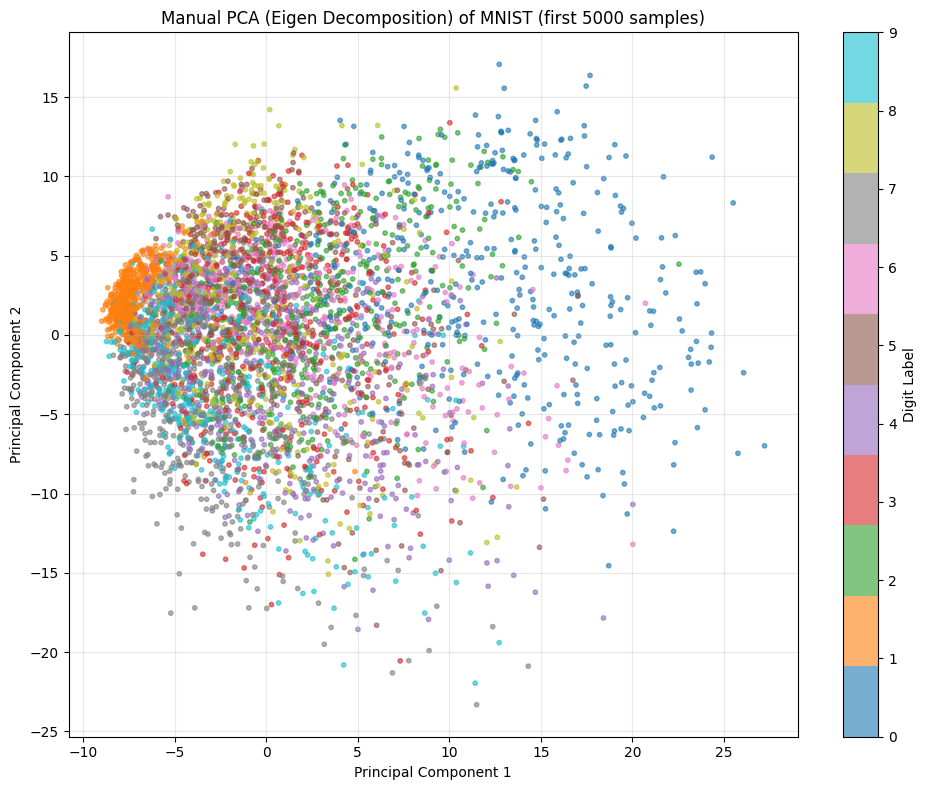

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
import numpy as np

# Load the MNIST dataset (flattened to 784 features)
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
X = mnist.data
y = mnist.target.astype(int)

# Standardize the data (zero mean, unit variance)
X_scaled = StandardScaler().fit_transform(X)

# Compute the covariance matrix (features x features)
cov_matrix = np.cov(X_scaled, rowvar=False)

# Compute eigenvalues and eigenvectors
eigvals, eigvecs = np.linalg.eigh(cov_matrix)

# Sort eigenvalues and eigenvectors in descending order
sorted_idx = np.argsort(eigvals)[::-1]
eigvals = eigvals[sorted_idx]
eigvecs = eigvecs[:, sorted_idx]

# Select the top 2 eigenvectors (principal components)
top2_eigvecs = eigvecs[:, :2]

# Project the data onto the top 2 principal components
X_pca_manual = np.dot(X_scaled, top2_eigvecs)

# Plot the 2D projection (first 5000 samples for speed)
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    X_pca_manual[:5000, 0],
    X_pca_manual[:5000, 1],
    c=y[:5000],
    cmap='tab10',
    alpha=0.6,
    s=10
)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Manual PCA (Eigen Decomposition) of MNIST (first 5000 samples)')
plt.colorbar(scatter, label='Digit Label')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()